# Appendix: a simulated referral world

**Simulated. Not field results.** Nothing on this page was observed in the field. Every number comes from a
simulation in which we invent the truth about each facility, then send simulated patients to them.

**Why simulate?** To answer the question a judge would ask: does the app get more patients to care in time than
sending them to the nearest listing, or to the "best" hospital on paper? Since the true answer is unknown for real
facilities, we invent several hidden truths and check whether the answer changes between them.

**Four hidden truths (scenarios), the first as two bounds.** Each result is shown for all of them, never for one
alone:
- **S0, "the text says nothing":** whether a facility offers the service depends only on the service and on the
  operator (public, private, unknown). Listing sentences and model scores carry no information. This is where the
  app can lose. The rate comes from few hand checks (about 15 decided pairs per service), so S0 is two bounds,
  always read together (simulated, base-rate bounds):
  - **S0-high:** confirmed among the decided checks (a "no information" check is left out);
  - **S0-low:** a "no information" check counts as "does not offer".
- **S1, "the model is right":** each facility offers the service with the probability our model gives. This is
  the app's best case, and circular, so it is never shown alone.
- **S2, "from our hand checks":** offer rates by service and by evidence stratum (strong, weak, suspect, not
  mentioned), from the web-checked DEV pairs. It does not use the model's scores.
- **S3, "the data is as bad as the audit says":** S2, plus sentences attributed to another facility are false,
  and map points are wrong at the audit's rate for their location rule (the true point is the alternative one).

S2 and S3 come from the same DEV labels the model's calibration step was fitted on, so they favour the app by
construction; S0 does not.

**Policies compared**, each trying at most 3 facilities before calling 108:
- **app:** the app as shipped (online answer; the offline state pack when there is no mobile data), phoning ahead;
- **app_offline:** the state pack only;
- **nearest:** the 3 nearest listings that name the service (by estimated travel time), no phone call;
- **nearest_call_first:** the same, phoning each one first like the app, so we can tell the value of the ranking
  from the value of calling ahead;
- **best_on_paper:** the 3 highest-scored listings in the state, ignoring distance.

One more policy, **app_before_101**, appears only in the "Ranking fix" section near the end: the app with the
emergency order it had before the simulation's first results.

Method, assumptions and honesty rules: [`sim/README.md`](../sim/README.md). Issue #92.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ON_DATABRICKS = "DATABRICKS_RUNTIME_VERSION" in os.environ
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sim" / "run.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from sim import world  # noqa: E402

if ON_DATABRICKS:
    dbutils.widgets.text("seeds", "20")  # noqa: F821 (dbutils is predefined on Databricks)
    dbutils.widgets.text("cases_per_seed", "200")  # noqa: F821
    SEEDS = int(dbutils.widgets.get("seeds"))  # noqa: F821
    CASES = int(dbutils.widgets.get("cases_per_seed"))  # noqa: F821
    OUT = Path("/Volumes/workspace/referral_saathi/uploads/sim")
else:  # the environment can change the run size
    SEEDS = int(os.environ.get("SIM_SEEDS", "20"))
    CASES = int(os.environ.get("SIM_CASES", "200"))  # per state x service x seed
    OUT = ROOT / "sim" / "out"
OUT.mkdir(parents=True, exist_ok=True)
SCENARIOS = list(world.SCENARIOS)  # S0-high, S0-low, S1, S2, S3
STATES = ["BIHAR", "UTTAR PRADESH"]
SERVICES = ["dialysis", "trauma_emergency"]
shown = OUT if ON_DATABRICKS else OUT.relative_to(ROOT)
print(f"SIMULATED run: {SEEDS} seeds x {CASES} cases per state and service, {STATES}, {SERVICES}, "
      f"output {shown}")

SIMULATED run: 20 seeds x 200 cases per state and service, ['BIHAR', 'UTTAR PRADESH'], ['dialysis', 'trauma_emergency'], output sim/out


## The run

For each seed: one set of simulated patients (origins at PIN code centres in Bihar and Uttar Pradesh, from
`sim/world.py`), the same for every policy and every scenario. Each policy picks its facilities once; the
scenario's hidden truth then decides what happens on the phone and at the door (`sim/execute.py`). The same coin
flips apply to the same patient at the same facility under every policy (common random numbers), so differences
come from the policies. Intervals are 90% seed-bootstrap intervals.

In [2]:
from sim.run import simulate, sweep_verdicts, table

res = simulate(SCENARIOS, list(range(SEEDS)), CASES, STATES, SERVICES, OUT, n_boot=500, sweep=True, verbose=False)
print("SIMULATED. World and truth: sim/world.py; executor: sim/execute.py; baselines: sim/policies_baseline.py")
print(f"{len(res['cases']):,} simulated cases, {len(res['events']):,} simulated events, {res['seconds']:.0f} s")

SIMULATED. World and truth: sim/world.py; executor: sim/execute.py; baselines: sim/policies_baseline.py
16,000 simulated cases, 2,408,127 simulated events, 156 s


## Simulated outcomes, by scenario

*Treated in window*: share of patients treated within the time window (60 min for trauma, 120 min for dialysis).
*Wasted trips*: arrivals turned away. *Unsafe first stop*: the first place travelled to does not exist or does not
offer the service. *Gave up*: three facilities tried without treatment (or time ran out), so the worker calls 108.
Both states pooled. S0-high and S0-low are printed together: they are bounds, not two results.

In [3]:
t = table(res["metrics"])
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print("\n=== S0, the text says nothing (SIMULATED, base-rate bounds: read high and low together) ===")
    print(t[t.scenario.str.startswith("S0")].sort_values(["service", "policy", "scenario"]).to_string(index=False))
    for sc in [s for s in SCENARIOS if not s.startswith("S0")]:
        print(f"\n=== {sc} (SIMULATED, not field results) ===")
        print(t[t.scenario == sc].drop(columns="scenario").to_string(index=False))


=== S0, the text says nothing (SIMULATED, base-rate bounds: read high and low together) ===
scenario          service             policy treated in window %    median min  wasted trips/case  calls/case  unsafe 1st stop %  gave up %  cases
 S0-high         dialysis                app          86 [86-87]    54 [54-55]               0.27        1.25                3.0        3.0   8000
  S0-low         dialysis                app          54 [52-56]    69 [67-71]               0.93        1.94               46.0       31.0   8000
 S0-high         dialysis        app_offline          87 [87-88]    51 [51-52]               0.28        1.25                3.0        3.0   8000
  S0-low         dialysis        app_offline          53 [51-56]    66 [64-68]               0.98        1.94               48.0       32.0   8000
 S0-high         dialysis      best_on_paper          24 [21-26] 209 [203-212]               0.45        0.00               10.0       12.0   8000
  S0-low         dialysis

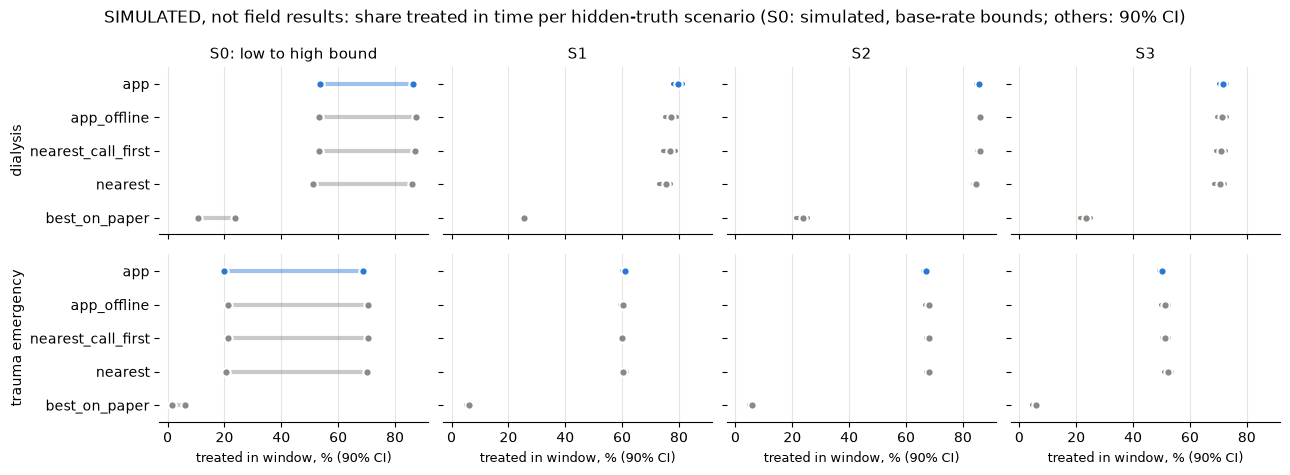

In [4]:
m = res["metrics"]
m = m[m.state == "ALL"]
policies = ["app", "app_offline", "nearest_call_first", "nearest", "best_on_paper"]
panels = ["S0", *[s for s in SCENARIOS if not s.startswith("S0")]]
fig, axes = plt.subplots(len(SERVICES), len(panels), figsize=(13, 4.8), sharex=True, sharey=True)
for i, svc in enumerate(SERVICES):
    for j, sc in enumerate(panels):
        ax = axes[i, j]
        d = m[m.service == svc]
        for k, pol in enumerate(policies):
            color = "#2a78d6" if pol == "app" else "#8a8984"
            if sc == "S0":  # the base-rate bounds: S0-low to S0-high, each a point estimate
                lo, hi = (100 * d[(d.scenario == b) & (d.policy == pol)].treated_in_window.iloc[0]
                          for b in ("S0-low", "S0-high"))
                ax.plot([lo, hi], [k, k], color=color, lw=3, alpha=0.45, solid_capstyle="round")
                ax.plot([lo, hi], [k, k], "o", ms=6, color=color, mec="white", mew=1.5)
                continue
            r = d[(d.scenario == sc) & (d.policy == pol)].iloc[0]
            ax.plot([100 * r.treated_in_window_lo, 100 * r.treated_in_window_hi], [k, k], color=color, lw=3,
                    solid_capstyle="round")
            ax.plot(100 * r.treated_in_window, k, "o", ms=6, color=color, mec="white", mew=1.5)
        ax.set_yticks(range(len(policies)), policies)
        ax.set_ylim(len(policies) - 0.5, -0.5)  # app on top
        ax.grid(axis="x", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
        for s in ("top", "right", "left"):
            ax.spines[s].set_visible(False)
        if i == 0:
            ax.set_title("S0: low to high bound" if sc == "S0" else sc, fontsize=11)
        if j == 0:
            ax.set_ylabel(svc.replace("_", " "), fontsize=10)
        if i == len(SERVICES) - 1:
            ax.set_xlabel("treated in window, % (90% CI)", fontsize=9)
fig.suptitle("SIMULATED, not field results: share treated in time per hidden-truth scenario "
             "(S0: simulated, base-rate bounds; others: 90% CI)", fontsize=12)
fig.tight_layout()
(OUT / "figures").mkdir(exist_ok=True)
fig.savefig(OUT / "figures" / "sim_treated_in_window.png", dpi=150)
plt.show()

## How much depends on the assumptions

The world needs numbers nobody has measured: how often a facility accepts a patient, how often a listed phone number
reaches it, how often a "yes" on the phone is wrong, and how often a facility is open (`world.KNOBS`). Each is set
low, middle and high in turn, with the others at the middle. The table shows **app minus nearest_call_first**, in
percentage points of patients treated in window, with a 90% interval. A level where the interval reaches zero or
below is a point where the app no longer beats the nearest listing called ahead.

In [5]:
s = res["sensitivity"].copy()
s["cell"] = ((100 * s["diff"]).round(1).astype(str) + " [" + (100 * s.diff_lo).round(1).astype(str) + ", "
             + (100 * s.diff_hi).round(1).astype(str) + "]" + s.app_beats.map({True: "", False: " *"}))
print("SIMULATED. app minus nearest_call_first, treated in window (points). * = app does not clearly beat it.")
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(s.pivot_table(index=["knob", "level"], columns=["scenario", "service"], values="cell",
                        aggfunc="first").to_string())
print("\nVerdict at the middle assumptions, and the swept levels where it changes (SIMULATED):")
with pd.option_context("display.width", 250, "display.max_colwidth", 120):
    print(sweep_verdicts(res["sensitivity"]).to_string(index=False))

SIMULATED. app minus nearest_call_first, treated in window (points). * = app does not clearly beat it.
scenario                      S0-high                                   S0-low                                   S1                                   S2                                      S3                     
service                      dialysis     trauma_emergency            dialysis     trauma_emergency        dialysis trauma_emergency            dialysis     trauma_emergency           dialysis     trauma_emergency
knob       level                                                                                                                                                                                                     
accept_p   high   -0.5 [-0.9, -0.2] *  -1.6 [-2.3, -1.0] *  -0.1 [-1.5, 1.4] *  -1.5 [-2.3, -0.7] *  2.4 [1.7, 3.2]   1.2 [0.6, 1.8]  -0.3 [-0.6, 0.1] *  -0.6 [-1.1, -0.1] *  0.4 [-0.6, 1.3] *  -0.9 [-1.4, -0.4] *
           low    -0.7 [-1.4, -0.0] *  -2

## Ranking fix found by the simulation

**Simulated, not field results.** The first runs of this simulation caught a flaw in how the app ordered emergency
options. For trauma it ranked by evidence discounted by travel time, p x exp(-minutes / 45), so a better documented
hospital farther away could come first. In every scenario that order treated fewer simulated patients within the
60-minute window than calling the nearest listings in turn (nearest_call_first): a "no" on the phone costs a few
minutes, a wasted trip costs the window. PR #101 changed the emergency order to the nearest place that plausibly
offers the care first (p only chooses among places within 5 minutes of the nearest one left, and never across the
window), with "call first, and if they say no, call the next". Planned care such as dialysis keeps the old order:
with a longer window, extra travel to a place with stronger evidence pays off, and its answers are unchanged.

The cell reruns the trauma cases with three policies: **app_before_101** (the same engine with the emergency order
switched back, for that policy only), **app** (as shipped) and nearest_call_first. Each app version minus
nearest_call_first, in points of patients treated within the window, with a 90% seed-bootstrap interval. The
change narrows the gap; the "verdict after" column shows the scenarios where the app still trails the nearest
listings called ahead.

In [6]:
from sim.run import compare, verdict

RANK_SEEDS, RANK_CASES = SEEDS, CASES  # trauma only, no sweep: about a minute locally at 20 seeds x 200 cases
rank = simulate(SCENARIOS, list(range(RANK_SEEDS)), RANK_CASES, STATES, ["trauma_emergency"], OUT / "rank_fix",
                n_boot=500, sweep=False, run_id="rank_fix", verbose=False,
                policies=["app_before_101", "app", "nearest_call_first"])


def cell(r: pd.Series) -> str:
    return f"{100 * r['diff']:+.1f} [{100 * r.diff_lo:+.1f}, {100 * r.diff_hi:+.1f}]"


before = compare(rank["outcomes"], "app_before_101", "nearest_call_first").set_index("scenario")
after = compare(rank["outcomes"], "app", "nearest_call_first").set_index("scenario")
fix = pd.DataFrame({
    "before #101 (app_before_101)": before.apply(cell, axis=1),
    "after #101 (app)": after.apply(cell, axis=1),
    "verdict after": [verdict(r.diff_lo, r.diff_hi) for r in after.itertuples()],
}).reindex(SCENARIOS)
fix["label"] = "SIMULATED"
print(f"SIMULATED, not field results. Trauma, {STATES}, {RANK_SEEDS} seeds x {RANK_CASES} cases per state, "
      f"{rank['seconds']:.0f} s.")
print("App minus nearest_call_first, treated within 60 min (points), 90% seed-bootstrap interval.")
print("S0-high and S0-low are simulated base-rate bounds: read them together.")
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(fix.to_string())

SIMULATED, not field results. Trauma, ['BIHAR', 'UTTAR PRADESH'], 20 seeds x 200 cases per state, 42 s.
App minus nearest_call_first, treated within 60 min (points), 90% seed-bootstrap interval.
S0-high and S0-low are simulated base-rate bounds: read them together.
         before #101 (app_before_101)   after #101 (app) verdict after      label
scenario                                                                         
S0-high             -7.5 [-8.6, -6.5]  -1.7 [-2.3, -1.1]     app worse  SIMULATED
S0-low              -4.1 [-5.1, -3.1]  -1.5 [-2.1, -0.8]     app worse  SIMULATED
S1                  -2.8 [-3.8, -1.8]  +1.0 [+0.4, +1.7]    app better  SIMULATED
S2                  -6.0 [-7.0, -4.9]  -1.0 [-1.5, -0.5]     app worse  SIMULATED
S3                  -5.5 [-6.6, -4.3]  -1.1 [-1.7, -0.5]     app worse  SIMULATED


## Limits

- **Simulated, not field results.** The hidden truths are built from our own data and the hand-checked DEV pairs;
  a real referral network will differ.
- Patients are drawn uniformly over PIN code centres, not by population (no population table is in the repo).
  Travel time is the travel estimate's middle value, with no spread.
- The call, turn-away and give-up times and the four swept knobs are assumptions; the size of any gap depends on
  them (see the sweep above). The S0 rate rests on about 15 decided checks per service, hence the two bounds.
- Two services and two states only. "App + field reports" and the multi-stop planner route are future work.
- S1 is circular: it assumes the model is right. Read it next to S0, where the listing text says nothing.